# Install dependencies


In [2]:
!pip install pymongo pandas numpy scikit-learn tensorflow motor nest_asyncio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.1/331.1 kB 17.7 MB/s eta 0:00:00


# Connect to MongoDB

In [3]:
from pymongo import MongoClient
import pandas as pd
import os
from google.colab import userdata

# Retrieve MongoDB connection string from Colab secrets
MONGO_URI = userdata.get('MONGO_URI')

# Establish connection to MongoDB
client = MongoClient(MONGO_URI)

# Select database and collection
db = client["SphereSleep"]
sensor_collection = db["sensor_data"]

# Load raw sensor data

In [4]:
# Fetch all records from MongoDB collection
data = list(sensor_collection.find())

# Convert to Pandas DataFrame
df = pd.DataFrame(data)

# View first rows
df.head()

,timestamp,user_id,_id,light_intensity,temperature,humidity,session_id,sound_level,distance,motion_detected
0,1970-01-01 00:00:05,user_001,69dbbef1fc40429a25bbc909,77.50,25.0,50.0,sleep_19700101_user001,18,0,0
1,1970-01-01 00:00:47,user_001,69debb2cb54b747ea1f37c52,4.17,25.0,50.0,sleep_19700101_user001,26,6,1
2,1970-01-01 00:00:49,user_001,69debb30b54b747ea1f37c53,4.17,25.0,50.0,sleep_19700101_user001,39,6,1
3,2026-04-01 21:45:03,user_001,69cd91e2fd35102c3c5ac1d1,5.00,27.5,55.3,sleep_20260401_user001,14,0,0
4,2026-04-01 21:45:04,user_001,69cd91e4fd35102c3c5ac1d2,5.00,27.5,55.3,sleep_20260401_user001,28,0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61318 entries, 0 to 61317
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   timestamp        61318 non-null  datetime64[ns]
 1   user_id          61318 non-null  object        
 2   _id              61318 non-null  object        
 3   light_intensity  61318 non-null  float64       
 4   temperature      61318 non-null  float64       
 5   humidity         61318 non-null  float64       
 6   session_id       61318 non-null  object        
 7   sound_level      61318 non-null  int64         
 8   distance         61318 non-null  int64         
 9   motion_detected  61318 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(3), object(3)
memory usage: 4.7+ MB


In [5]:
# Sort data by timestamp (important for time-series analysis)
df = df.sort_values("timestamp")

# Filter out invalid/old timestamps
df = df[df['timestamp'] > pd.to_datetime('2020-01-01 00:00:00')]

# Set timestamp as index for resampling
df = df.set_index("timestamp")

In [ ]:
df

,user_id,_id,light_intensity,temperature,humidity,session_id,sound_level,distance,motion_detected
timestamp,,,,,,,,,
2026-04-01 21:45:03,user_001,69cd91e2fd35102c3c5ac1d1,5.00,27.5,55.3,sleep_20260401_user001,14,0,0
2026-04-01 21:45:04,user_001,69cd91e4fd35102c3c5ac1d2,5.00,27.5,55.3,sleep_20260401_user001,28,0,0
2026-04-01 21:45:05,user_001,69cd91e5fd35102c3c5ac1d3,4.17,26.6,56.0,sleep_20260401_user001,41,0,1
2026-04-01 21:45:07,user_001,69cd91e6fd35102c3c5ac1d4,5.00,26.6,56.0,sleep_20260401_user001,55,0,0
2026-04-01 21:45:08,user_001,69cd91e8fd35102c3c5ac1d5,4.17,26.6,56.0,sleep_20260401_user001,68,0,1
...,...,...,...,...,...,...,...,...,...
2026-04-16 02:48:30,user_001,69e04dff53563f4013defd9d,28.33,25.0,50.0,sleep_20260416_user001,181,9,0
2026-04-16 02:48:32,user_001,69e04e0153563f4013defd9e,28.33,25.0,50.0,sleep_20260416_user001,182,9,0
2026-04-16 02:48:34,user_001,69e04e0253563f4013defd9f,28.33,25.0,50.0,sleep_20260416_user001,183,9,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 61315 entries, 2026-04-01 21:45:03 to 2026-04-16 02:48:38
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   user_id          61315 non-null  object 
 1   _id              61315 non-null  object 
 2   light_intensity  61315 non-null  float64
 3   temperature      61315 non-null  float64
 4   humidity         61315 non-null  float64
 5   session_id       61315 non-null  object 
 6   sound_level      61315 non-null  int64  
 7   distance         61315 non-null  int64  
 8   motion_detected  61315 non-null  int64  
dtypes: float64(3), int64(3), object(3)
memory usage: 4.7+ MB


In [ ]:
df['distance'].describe()

,distance
count,61315.000000
mean,12.858681
std,35.222590
min,0.000000
25%,0.000000
50%,0.000000
75%,15.000000
max,373.000000


# Create 10-minute windows

In [6]:
# Group data into 10-minute windows
windows = df.resample("10min")

# Feature extraction function

In [7]:
import numpy as np

def extract_features(window):
    """
    Extract statistical features from each 10-minute window.
    These features represent sleep environment conditions.
    """

    # Ignore very small windows (noise)
    if len(window) < 5:
        return None

    # Sensor signals
    sound = window["sound_level"]
    light = window["light_intensity"]
    temp = window["temperature"]
    humidity = window["humidity"]
    motion = window["motion_detected"]

    return {
        # Sound features (sleep disturbance indicator)
        "acd_mean": sound.mean(),
        "acd_max": sound.max(),
        "sound_std": sound.std(),
        "spike_count": (sound > sound.mean() + sound.std()).sum(),

        # Motion activity (restlessness indicator)
        "motion_rate": motion.mean(),

        # Light exposure (sleep disruption factor)
        "light_avg": light.mean(),
        "light_std": light.std(),
        "light_duration": (light > 20).sum(),

        # Environmental stability
        "temp_std": temp.std(),
        "humidity_std": humidity.std()
    }

# Build Feature Dataset

In [8]:
records = []

# Iterate through each time window
for _, window in windows:
    features = extract_features(window)

    # Only keep valid feature sets
    if features is not None:
        records.append(features)

# Convert extracted features into DataFrame
X = pd.DataFrame(records)

print(X.shape)
X

min_vals = X.min().values
max_vals = X.max().values

print(min_vals)
print(max_vals)

(223, 10)
[45.91608392 64.          1.93621911  0.          0.          1.67
  0.          0.          0.          0.        ]
[3.83005988e+02 4.05000000e+02 1.00483216e+02 1.01000000e+02
 4.00000000e-01 1.43598023e+02 3.17831299e+01 2.89000000e+02
 1.43649369e+00 4.58741655e+00]


# Normalize features

In [9]:
Xn = X.copy()

# Min-max normalization for each feature (0–1 range)
for col in X.columns:
    Xn[col] = (X[col] - X[col].min()) / (X[col].max() - X[col].min() + 1e-8)

# View normalized statistics
print(Xn.describe())

         acd_mean     acd_max   sound_std  spike_count  motion_rate  \
count  223.000000  223.000000  223.000000   223.000000   223.000000   
mean     0.156969    0.153071    0.072052     0.297296     0.166988   
std      0.165181    0.178082    0.103031     0.230887     0.234086   
min      0.000000    0.000000    0.000000     0.000000     0.000000   
25%      0.058369    0.046921    0.018722     0.049505     0.000000   
50%      0.098576    0.079179    0.032437     0.326733     0.019305   
75%      0.162100    0.168622    0.097847     0.455446     0.296721   
max      1.000000    1.000000    1.000000     1.000000     1.000000   

        light_avg   light_std  light_duration    temp_std  humidity_std  
count  223.000000  223.000000      223.000000  223.000000    223.000000  
mean     0.107155    0.051488        0.114435    0.094272      0.131397  
std      0.225101    0.131388        0.275206    0.135280      0.153109  
min      0.000000    0.000000        0.000000    0.000000      0

# Physics based score function

In [10]:
def compute_physics_score(df, ks=0.5):
    """
    Converts sensor features into sleep score using weighted physics model.
    Output:
        score → higher = better sleep
        D → disturbance score
    """

    S = df['acd_mean']**2 + (df['acd_max'] - df['acd_mean'])**2 + ks * df['spike_count']**2
    M = df['motion_rate']**2
    L = df['light_avg'] * df['light_duration']
    T = df['temp_std']**2
    H = df['humidity_std']**2

    # Combined disturbance score
    D = 0.35*S + 0.30*M + 0.15*L + 0.10*T + 0.10*H

    # Convert disturbance into sleep score
    score = 100 / (1 + D)

    return score, D

In [11]:
# Compute disturbance and score
score, D = compute_physics_score(Xn)

# Check range of disturbance
print(D.min(), D.max())

y = 100 / (1 + D)

# Final sleep score target
y_final = y
X_final = Xn

0.0026538816124230713 0.4784658747316982


In [ ]:
X_final

,acd_mean,acd_max,sound_std,spike_count,motion_rate,light_avg,light_std,light_duration,temp_std,humidity_std
0,0.080230,0.087977,0.081756,0.049505,0.171569,0.022889,0.007804,0.000000,0.161992,0.110210
1,0.087809,0.049853,0.003571,0.386139,0.000000,0.022183,0.010824,0.000000,0.132625,0.234483
2,0.084789,0.046921,0.002482,0.792079,0.000000,0.009126,0.029471,0.000000,0.101669,0.222169
3,0.084689,0.049853,0.003640,0.752475,0.000000,0.005848,0.000000,0.000000,0.094388,0.235115
4,0.083987,0.049853,0.005986,0.702970,0.011136,0.005848,0.000000,0.000000,0.108229,0.275411
...,...,...,...,...,...,...,...,...,...,...
218,0.388307,0.416422,0.279147,0.000000,0.254386,0.173452,0.044910,0.986159,0.000000,0.000000
219,0.381694,0.363636,0.218535,0.000000,0.043253,0.186423,0.026559,1.000000,0.000000,0.000000
220,0.386354,0.360704,0.187570,0.000000,0.181661,0.103788,0.219322,0.311419,0.000000,0.000000
221,0.375112,0.366569,0.277370,0.000000,0.576923,0.080975,0.025372,0.000000,0.000000,0.000000


In [ ]:
y_final

,0
0,98.486045
1,96.473595
2,89.383007
3,90.216710
4,91.062277
...,...
218,91.064570
219,92.624292
220,93.701117
221,87.022672


In [ ]:
y_final.min()

67.63767883255832

In [ ]:
y_final.max()

99.73531428331428

In [ ]:
import json

feature_names = [
    "acd_mean",
    "acd_max",
    "sound_std",
    "spike_count",
    "motion_rate",
    "light_avg",
    "light_std",
    "light_duration",
    "temp_std",
    "humidity_std"
]

records = []

for i in range(len(X_final)):
    records.append({
        "type": "ml",
        "sleep_score": float(y_final.iloc[i]),
        "features": dict(zip(feature_names, X_final.iloc[i])),
        "session_id": df["session_id"].iloc[i]   # ✅ FIXED
    })

In [ ]:
with open("ml_data.json", "w") as f:
    json.dump(records, f, indent=2)

In [ ]:
from google.colab import files
files.download("ml_data.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
from motor.motor_asyncio import AsyncIOMotorClient
import asyncio
from google.colab import userdata
import nest_asyncio

nest_asyncio.apply()

MONGO_URI = userdata.get('MONGO_URI')

client = AsyncIOMotorClient(MONGO_URI)
db = client.SphereSleep
ml_collection = db["ml_data"]

async def insert():
    with open("ml_data.json", "r") as f:
        data = json.load(f)

    # ✅ FIX: handle both list and wrapped formats
    if isinstance(data, dict) and "records" in data:
        data = data["records"]

    if not isinstance(data, list):
        raise ValueError("Data must be a list of documents")

    result = await ml_collection.insert_many(data)
    print("Inserted:", len(result.inserted_ids))

loop = asyncio.get_event_loop()
loop.run_until_complete(insert())

Inserted: 223


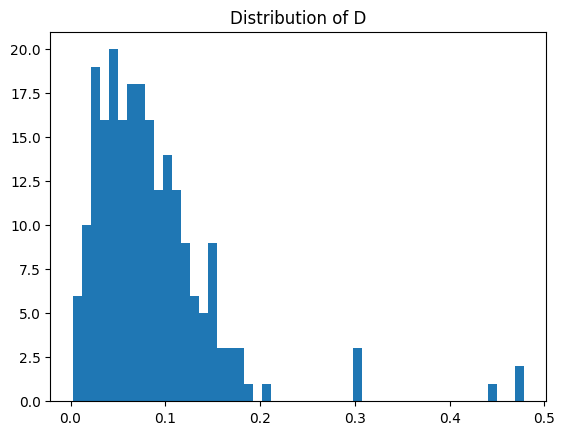

In [12]:
import matplotlib.pyplot as plt

plt.hist(D, bins=50)
plt.title("Distribution of D")
plt.show()

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_final,
    test_size=0.2,
    random_state=42
)

In [14]:
from sklearn.linear_model import Ridge

model = Ridge(alpha=1.0)
model.fit(X_train, y_train)

Ridge()

In [15]:
print("Train R2:", model.score(X_train, y_train))
print("Test R2:", model.score(X_test, y_test))

Train R2: 0.8236699578067813
Test R2: 0.8714153597179225


In [16]:
print("Bias:", model.intercept_)
print("Weights:", model.coef_)

Bias: 101.70629255440075
Weights: [ -7.40311891  -6.68688923  -1.51474016  -9.73226432 -14.152192
  -5.84967805  -0.27114583  -2.19286357  -3.26428404  -3.26570277]


In [17]:
feature_names = X_train.columns  # if DataFrame

for name, weight in zip(feature_names, model.coef_):
    print(name, weight)

acd_mean -7.403118912076956
acd_max -6.686889230985416
sound_std -1.5147401605354924
spike_count -9.732264315023926
motion_rate -14.152192003636953
light_avg -5.849678046712621
light_std -0.27114582696621137
light_duration -2.1928635707485156
temp_std -3.2642840427362483
humidity_std -3.265702773260537


In [18]:
y_pred = model.predict(X_test)

In [19]:
import pandas as pd

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results.head(10)

,Actual,Predicted
0,90.248071,91.105581
1,85.610647,87.971551
2,96.227870,95.444205
3,91.443797,91.208512
4,93.701117,92.229563
5,97.397687,96.430176
6,95.503352,95.379858
7,97.676340,96.258350
8,87.292753,90.829199
9,99.302896,98.055993


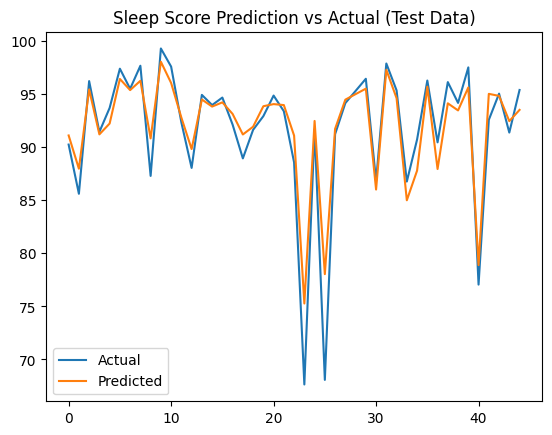

In [20]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(y_test.values[:50], label="Actual")
plt.plot(y_pred[:50], label="Predicted")
plt.legend()
plt.title("Sleep Score Prediction vs Actual (Test Data)")
plt.show()

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))


print("MAE:", mae)
print("RMSE:", rmse)

MAE: 1.5248666827076016
RMSE: 2.3489944195513486


In [22]:
import numpy as np

# Example: one new sample with 10 features
new_sample = np.array([[0.5, 0.7, 0.3, 2, 0.4, 0.6, 0.2, 10, 0.5, 0.3]])

# Predict sleep score
predicted_score = model.predict(new_sample)

print("Predicted Sleep Score:", predicted_score[0])

Predicted Sleep Score: 39.639558602756935


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Ridge was fitted with feature names
  warnings.warn(
